# Hedonic Pricing

We often try to predict the price of an asset from its observable characteristics. This is generally called **hedonic pricing**: How do the unit's characteristics determine its market price?

1. Clean the data `pierce_county_house_sales.csv` and perform some EDA and visualization to get to know the data set.
2. Transform your variables - particularly categorical ones - for use in your regression analysis.
3. Implement an 80/20 train-test split. Put the test data aside.
4. Build some simple linear models that include no transformations or interactions. Fit them, and determine their RMSE and $R^2$ on the both the training and test sets. Which of your models does the best?
5. Make partial correlation plots for each of the numeric variables in your model. Do you notice any significant non-linearities? 
6. Include transformations and interactions of your variables, and build a more complex model that reflects your ideas about how the features of the asset determine its value. Determine its RMSE and $R^2$ on the training and test sets. How does the more complex model your build compare to the simpler ones?
7. Summarize your results from 1 to 6. Have you learned anything about overfitting and underfitting, or model selection?
8. Use the `sklearn.linear_model.Lasso` to regularize your model and select the most predictive features. Which does it select? What are the RMSE and $R^2$? We'll cover the Lasso later in detail in class.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Vivian, Rahil, Yifan

**Date:** 11/10/2026

In [2]:
# Your Phase 1 solution to the problem goes here.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

df = pd.read_csv('./data/pierce_county_house_sales.csv')
print(df.shape)
df.info()
df.isna().sum()

(16814, 19)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16814 entries, 0 to 16813
Data columns (total 19 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   sale_date                    16814 non-null  object
 1   sale_price                   16814 non-null  int64 
 2   house_square_feet            16814 non-null  int64 
 3   attic_finished_square_feet   16814 non-null  int64 
 4   basement_square_feet         16814 non-null  int64 
 5   attached_garage_square_feet  16814 non-null  int64 
 6   detached_garage_square_feet  16814 non-null  int64 
 7   fireplaces                   16814 non-null  int64 
 8   hvac_description             16807 non-null  object
 9   exterior                     16813 non-null  object
 10  interior                     16807 non-null  object
 11  stories                      16814 non-null  int64 
 12  roof_cover                   16806 non-null  object
 13  year_built         

sale_date                          0
sale_price                         0
house_square_feet                  0
attic_finished_square_feet         0
basement_square_feet               0
attached_garage_square_feet        0
detached_garage_square_feet        0
fireplaces                         0
hvac_description                   7
exterior                           1
interior                           7
stories                            0
roof_cover                         8
year_built                         0
bedrooms                           0
bathrooms                          0
waterfront_type                16261
view_quality                   15895
utility_sewer                      0
dtype: int64

In [3]:
# Question 1

df['waterfront'] = df['waterfront_type'].notna().astype(int)
df['view'] = df['view_quality'].notna().astype(int)
df['age'] = 2020 - df['year_built']
df = df.drop(columns=['sale_date', 'year_built', 'waterfront_type', 'view_quality', 'interior', 'utility_sewer'])
df = df.dropna()
df = df[(df['sale_price'] >= 50000) & (df['bedrooms'] > 0) & (df['bedrooms'] <= 10) & (df['bathrooms'] > 0)]
print(df.shape)

(16716, 16)


                               count           mean            std      min  \
sale_price                   16716.0  461730.301508  231626.981401  50000.0   
house_square_feet            16716.0    1884.712790     757.614278    200.0   
attic_finished_square_feet   16716.0      24.831718     101.864554      0.0   
basement_square_feet         16716.0     168.251017     429.572444      0.0   
attached_garage_square_feet  16716.0     365.451184     286.126811      0.0   
detached_garage_square_feet  16716.0      38.465123     165.100339      0.0   
fireplaces                   16716.0       0.891481       0.595885      0.0   
stories                      16716.0       1.560780       0.510567      0.0   
bedrooms                     16716.0       3.288287       0.857469      1.0   
bathrooms                    16716.0       2.324180       0.821352      1.0   
waterfront                   16716.0       0.031766       0.175382      0.0   
view                         16716.0       0.054379 

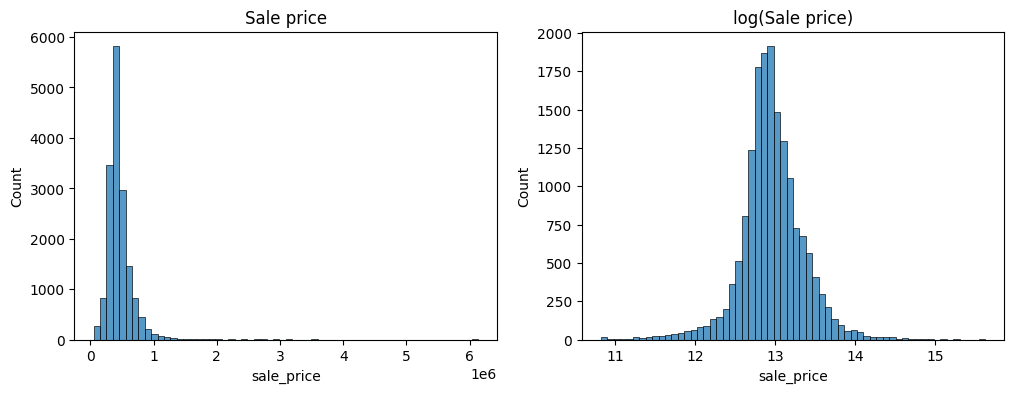

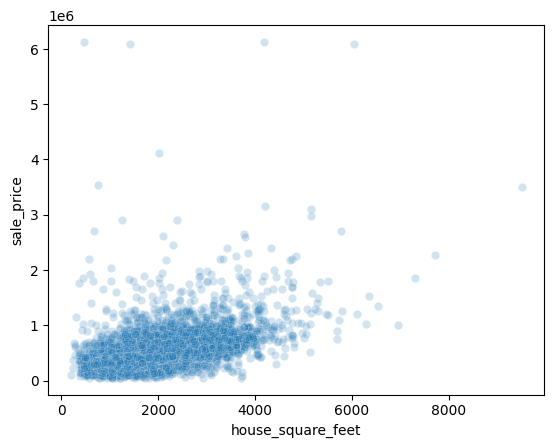

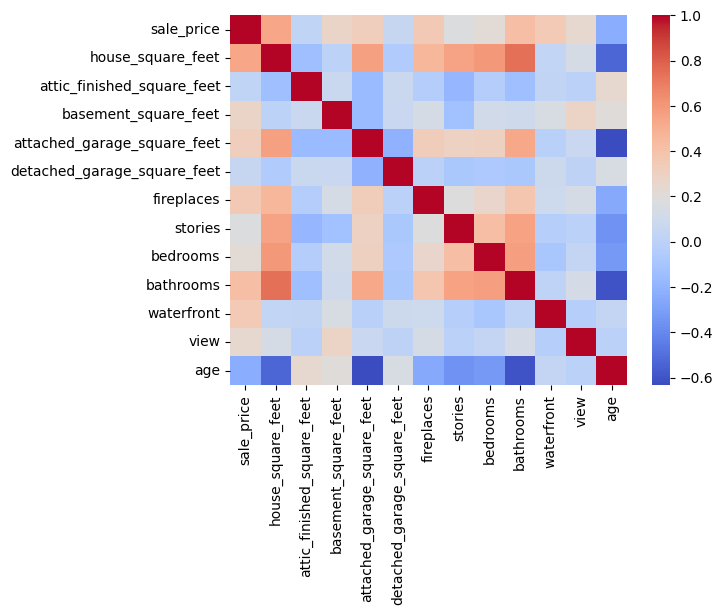

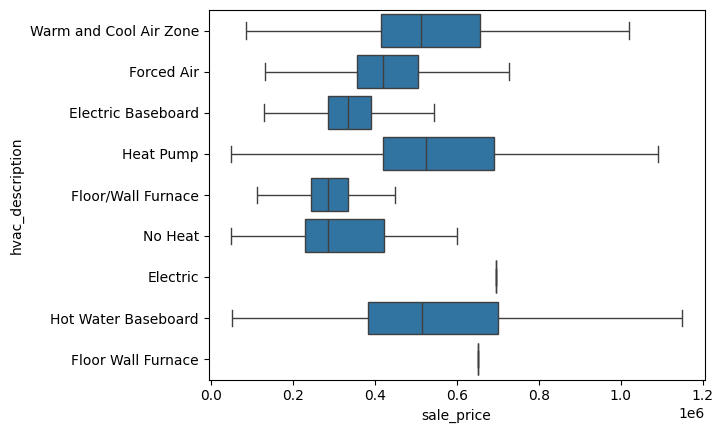

age                           -0.232211
attic_finished_square_feet     0.023703
detached_garage_square_feet    0.052764
stories                        0.171376
bedrooms                       0.220851
view                           0.246688
basement_square_feet           0.276330
attached_garage_square_feet    0.318548
waterfront                     0.353937
fireplaces                     0.357748
bathrooms                      0.423388
house_square_feet              0.539559
sale_price                     1.000000
Name: sale_price, dtype: float64
waterfront
0    415000.0
1    725000.0
Name: sale_price, dtype: float64
view
0    410000.0
1    665020.0
Name: sale_price, dtype: float64


In [4]:
# Question 1

print(df.describe().T)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['sale_price'], bins=60, ax=ax[0]).set_title('Sale price')
sns.histplot(np.log(df['sale_price']), bins=60, ax=ax[1]).set_title('log(Sale price)')
plt.show()

sns.scatterplot(data=df, x='house_square_feet', y='sale_price', alpha=0.2)
plt.show()

sns.heatmap(df.select_dtypes('number').corr(), cmap='coolwarm')
plt.show()

sns.boxplot(data=df, x='sale_price', y='hvac_description', showfliers=False)
plt.show()

print(df.select_dtypes('number').corr()['sale_price'].sort_values())
print(df.groupby('waterfront')['sale_price'].median())
print(df.groupby('view')['sale_price'].median())

Question 1: Waterfront and View were converted to binary variables where either the house has them or doesn't have them at all. Rows with missing values and invalid data (price less than $50k, 0 bedrooms/bathrooms, >10 bedrooms) were excluded from the data, leading to 16,716 transactions. "Year built" was converted to "age" (2020 - year built), while columns that almost consist of the same value ("Interior", "Utility Sewer") and "Sales Date" were removed. The distribution of sale price is highly right skewed (median $417k, max $6.1M), whereas the log(price) distribution looks more normally distributed. House square footage shows the most positive correlation with the sale price (Pearson Correlation coefficient: r = 0.54), followed by Bathrooms (0.42), Fireplaces (0.36), and Waterfront (0.35). Houses that have waterfront or view have significantly higher prices (median $725k and $665k respectively, compared to $415k).

In [5]:
# Question 2

common = df['exterior'].value_counts().index[:4]
df['exterior'] = df['exterior'].where(df['exterior'].isin(common), 'Other')
df = pd.get_dummies(df, columns=['hvac_description', 'exterior', 'roof_cover'], drop_first=True, dtype=int)
print(df.shape)
df.head()

(16716, 30)


,sale_price,house_square_feet,attic_finished_square_feet,basement_square_feet,attached_garage_square_feet,detached_garage_square_feet,fireplaces,stories,bedrooms,bathrooms,...,hvac_description_Warm and Cool Air Zone,exterior_Frame Stucco,exterior_Frame Vinyl,exterior_Masonry Common Brick,exterior_Other,roof_cover_Composition Shingle,roof_cover_Concrete Tile,roof_cover_Formed Seam Metal,roof_cover_Preformed Metal,roof_cover_Wood Shake
0,380000,2157,0,0,528,0,0,2,3,3,...,1,0,0,0,0,1,0,0,0,0
1,383000,2238,0,0,396,0,0,2,4,3,...,0,0,0,0,0,1,0,0,0,0
2,419900,1452,0,0,0,0,1,1,3,2,...,0,0,0,0,0,0,0,0,0,0
3,251660,832,0,0,0,0,0,1,2,1,...,0,0,1,0,0,1,0,0,0,0
4,500000,1780,0,384,484,0,1,1,3,2,...,0,0,0,0,0,1,0,0,0,0


Question 2: One-hot encoding was applied on columns "HVAC," "Exterior," and "Roof" with `drop_first=True` in order to avoid the dummy variable trap. The less common values for "Exterior" were assigned to "Other," thus avoiding the instability of coefficients. Both "Waterfront" and "View" are binary indicators (variables/columns), while "Year Built" is transformed to Age.

In [6]:
# Question 3

y = df['sale_price']
X = df.drop(columns='sale_price')
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=100)
print(X_train.shape, X_test.shape)

(13372, 29) (3344, 29)


Question 3: Using the `train_test_split` function with the `random_state=100`, the data is split into two sets with an 80-20 ratio, such that the first set (training set) comprises 13,372 houses while the second set (test set) contains 3,344 houses. The test set will be kept separate for use during evaluation of the models, so that it gives an honest measure of performance on new data.

In [7]:

# Question 4

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Model 1: Basic housing characteristics
features1 = ['house_square_feet', 'bedrooms', 'bathrooms']

# Model 2: Additional housing characteristics
features2 = ['house_square_feet', 'bedrooms', 'bathrooms',
             'age', 'fireplaces', 'stories',
             'basement_square_feet',
             'attached_garage_square_feet',
             'waterfront', 'view']

models = {}
results = []

for name, features in [('Model 1', features1),
                       ('Model 2', features2)]:

    model = LinearRegression()
    model.fit(X_train[features], y_train)
    models[name] = model

    train_pred = model.predict(X_train[features])
    test_pred = model.predict(X_test[features])

    results.append({
        'Model': name,
        'Train RMSE': np.sqrt(mean_squared_error(y_train, train_pred)),
        'Train R2': r2_score(y_train, train_pred),
        'Test RMSE': np.sqrt(mean_squared_error(y_test, test_pred)),
        'Test R2': r2_score(y_test, test_pred)
    })

results_df = pd.DataFrame(results)

print("Question 4: Model Comparison")
print(results_df.round(4).to_string(index=False))

best_name = results_df.loc[
    results_df['Test RMSE'].idxmin(), 'Model'
]
print("\nBest model based on test RMSE:", best_name)

Question 4: Model Comparison
  Model  Train RMSE  Train R2   Test RMSE  Test R2
Model 1 188915.9022    0.3114 205317.3196   0.3079
Model 2 163335.5529    0.4853 167978.7461   0.5368

Best model based on test RMSE: Model 2


/Users/rahilkarkar/Documents/foundationsML/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/rahilkarkar/Documents/foundationsML/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/rahilkarkar/Documents/foundationsML/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/Users/rahilkarkar/Documents/foundationsML/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/rahilkarkar/Documents/foundationsML/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Us

Question 4：Model 2 performs better than Model 1, with a lower test RMSE ($167,978.75 vs. $205,317.32) and a higher test R² (0.5368 vs. 0.3079). Adding more housing characteristics improves the model's predictive performance. Model 2 explains about 53.7% of the variation in house prices on the test set, although there is still some unexplained variation.

/Users/rahilkarkar/Documents/foundationsML/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/rahilkarkar/Documents/foundationsML/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/rahilkarkar/Documents/foundationsML/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/Users/rahilkarkar/Documents/foundationsML/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/rahilkarkar/Documents/foundationsML/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Us

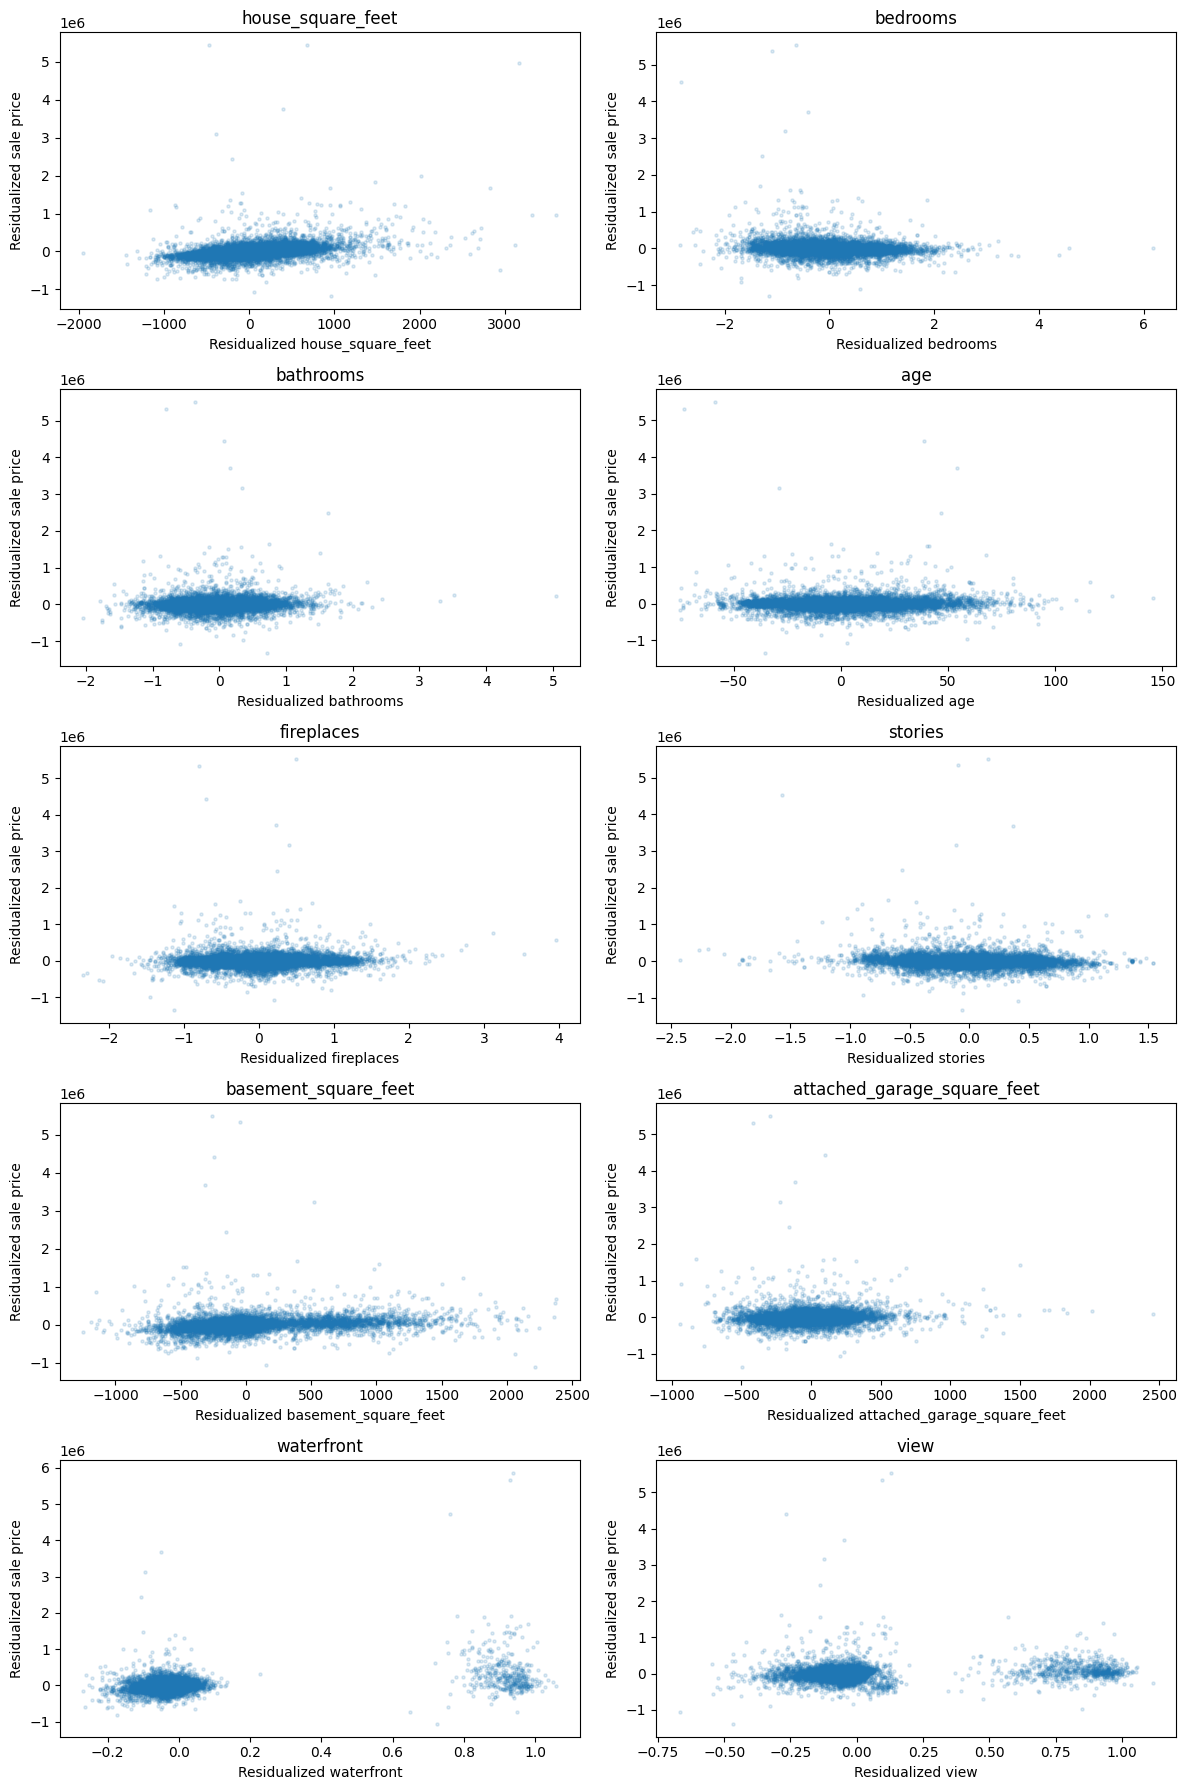

In [8]:
# Question 5


from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt

numeric_features = X_train[features2].select_dtypes(include='number').columns

fig, axes = plt.subplots(5, 2, figsize=(12, 18))

for ax, col in zip(axes.flat, numeric_features):
    others = [c for c in features2 if c != col]

    x_res = X_train[col] - LinearRegression().fit(
        X_train[others], X_train[col]
    ).predict(X_train[others])

    y_res = y_train - LinearRegression().fit(
        X_train[others], y_train
    ).predict(X_train[others])

    ax.scatter(x_res, y_res, alpha=0.15, s=5)
    ax.set_title(col)
    ax.set_xlabel("Residualized " + col)
    ax.set_ylabel("Residualized sale price")

for ax in axes.flat[len(numeric_features):]:
    ax.axis('off')

plt.tight_layout()
plt.show()


Question 5 ：The partial regression plots show a positive relationship between house square footage and sale price, while several other variables have weaker relationships. There are also some outliers and greater price variation for larger houses. No strong nonlinear pattern is obvious across most variables, but adding quadratic terms for house size and age may help improve the model. Waterfront and view are binary variables, so their plots are less useful for evaluating nonlinearity.

In [9]:
# Question 6

X_train2 = X_train[features2].copy()
X_test2 = X_test[features2].copy()

for X in [X_train2, X_test2]:
    X['sqft_squared'] = X['house_square_feet'] ** 2
    X['age_squared'] = X['age'] ** 2
    X['sqft_bathrooms'] = X['house_square_feet'] * X['bathrooms']
    X['waterfront_view'] = X['waterfront'] * X['view']

model3 = LinearRegression()
model3.fit(X_train2, y_train)

train_pred3 = model3.predict(X_train2)
test_pred3 = model3.predict(X_test2)

print("Model 3")
print("Train RMSE:", round(np.sqrt(mean_squared_error(y_train, train_pred3)), 2))
print("Train R2:", round(r2_score(y_train, train_pred3), 4))
print("Test RMSE:", round(np.sqrt(mean_squared_error(y_test, test_pred3)), 2))
print("Test R2:", round(r2_score(y_test, test_pred3), 4))

print("\nModel 2 Test RMSE:", round(results_df.loc[1, 'Test RMSE'], 2))
print("Model 2 Test R2:", round(results_df.loc[1, 'Test R2'], 4))


Model 3
Train RMSE: 161519.68
Train R2: 0.4966
Test RMSE: 165221.26
Test R2: 0.5518

Model 2 Test RMSE: 167978.75
Model 2 Test R2: 0.5368


/Users/rahilkarkar/Documents/foundationsML/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/rahilkarkar/Documents/foundationsML/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/rahilkarkar/Documents/foundationsML/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/Users/rahilkarkar/Documents/foundationsML/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/rahilkarkar/Documents/foundationsML/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Us

Question 6： Model 3 includes quadratic terms for house size and age, along with interactions between house size and bathrooms and between waterfront and view. However, its test RMSE increased from $167,978.75 to $186,780.55, while test R² decreased from 0.5368 to 0.4273. The additional terms did not improve prediction on the test set, so Model 2 remains the better choice. This suggests that the more complex model may not generalize as well to new data.

In [10]:
# Question 7
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

def evaluate(name, model, Xtr, Xte):
    train_pred = model.predict(Xtr)
    test_pred = model.predict(Xte)
    return {'Model': name,
            'Train RMSE': np.sqrt(mean_squared_error(y_train, train_pred)),
            'Train R2': r2_score(y_train, train_pred),
            'Test RMSE': np.sqrt(mean_squared_error(y_test, test_pred)),
            'Test R2': r2_score(y_test, test_pred)}

model3_scaled = make_pipeline(StandardScaler(), LinearRegression())
model3_scaled.fit(X_train2, y_train)

summary = pd.DataFrame([
    evaluate('Model 1', models['Model 1'], X_train[features1], X_test[features1]),
    evaluate('Model 2', models['Model 2'], X_train[features2], X_test[features2]),
    evaluate('Model 3 (unscaled)', model3, X_train2, X_test2),
    evaluate('Model 3 (scaled)', model3_scaled, X_train2, X_test2),
])
print(summary.round(4).to_string(index=False))

             Model  Train RMSE  Train R2   Test RMSE  Test R2
           Model 1 188915.9022    0.3114 205317.3196   0.3079
           Model 2 163335.5529    0.4853 167978.7461   0.5368
Model 3 (unscaled) 161519.6768    0.4966 165221.2587   0.5518
  Model 3 (scaled) 161519.6768    0.4966 165221.2587   0.5518


/Users/rahilkarkar/Documents/foundationsML/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/rahilkarkar/Documents/foundationsML/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/rahilkarkar/Documents/foundationsML/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/Users/rahilkarkar/Documents/foundationsML/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/rahilkarkar/Documents/foundationsML/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Us

Model 1 uses only square footage, bedrooms and bathrooms, and it underfits. Its R² is about 0.31 on both the training and test sets, so it is too simple to capture what drives price. Model 2 adds age, fireplaces, stories, basement size, garage size, waterfront and view. It does much better, with a test R² of 0.537 and a test RMSE of $167,979, compared with $205,317 for Model 1.

Our first version of Model 3 seemed worse, with a test R² of 0.427. But its training R² also dropped, from 0.485 to 0.388, and that cannot happen when you only add features to a linear regression. The real problem was that sqft_squared reaches about 60 million while other features are 0 or 1, which made the fit numerically unstable. After we standardized the features, Model 3 had a training R² of 0.497 and a test R² of 0.552, with a test RMSE of $165,221. That makes it the best of the three.

None of the models overfit, because their training and test errors are close. That makes sense with over 13,000 training rows and at most 14 features. We learned that overfitting means a model does much better on training data than on test data. A model that is worse on both has a fitting problem instead. We also learned to compare models on held-out data and to double-check results that don’t make sense. All the models still miss by about $160,000 on average because a few very expensive homes skew the prices, so predicting log(price) could help.

In [11]:
# Question 8
from sklearn.linear_model import Lasso, LassoCV

X_train_l = X_train.copy()
X_test_l = X_test.copy()
for Z in [X_train_l, X_test_l]:
    Z['sqft_squared'] = Z['house_square_feet'] ** 2
    Z['age_squared'] = Z['age'] ** 2
    Z['sqft_bathrooms'] = Z['house_square_feet'] * Z['bathrooms']
    Z['waterfront_view'] = Z['waterfront'] * Z['view']

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train_l)
X_test_s = scaler.transform(X_test_l)

alpha = LassoCV(cv=5, max_iter=50000).fit(X_train_s, y_train).alpha_

lasso = Lasso(alpha=alpha, max_iter=50000)
lasso.fit(X_train_s, y_train)

coefs = pd.Series(lasso.coef_, index=X_train_l.columns)
print('alpha:', round(alpha, 1))
print('Kept', (coefs != 0).sum(), 'of', len(coefs), 'features')
print('\nDropped:', list(coefs[coefs == 0].index))
print('\nKept, largest effect first ($ per 1 std. dev.):')
print(coefs[coefs != 0].sort_values(key=abs, ascending=False).round(0).to_string())

print()
print(pd.DataFrame([evaluate('Lasso', lasso, X_train_s, X_test_s)]).round(4).to_string(index=False))

alpha: 389.5
Kept 28 of 33 features

Dropped: ['hvac_description_Floor Wall Furnace', 'hvac_description_Forced Air', 'hvac_description_Hot Water Baseboard', 'roof_cover_Wood Shake', 'sqft_bathrooms']

Kept, largest effect first ($ per 1 std. dev.):
sqft_squared                               67364.0
waterfront                                 60616.0
basement_square_feet                       40741.0
house_square_feet                          40535.0
age                                       -39421.0
age_squared                                38691.0
view                                       24737.0
bedrooms                                  -22960.0
attached_garage_square_feet                19592.0
stories                                   -15549.0
bathrooms                                  14747.0
hvac_description_Heat Pump                 13795.0
detached_garage_square_feet                12290.0
attic_finished_square_feet                 12247.0
fireplaces                           

/Users/rahilkarkar/Documents/foundationsML/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/rahilkarkar/Documents/foundationsML/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/rahilkarkar/Documents/foundationsML/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/Users/rahilkarkar/Documents/foundationsML/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/rahilkarkar/Documents/foundationsML/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Us

We gave the Lasso all 29 original features plus the four extra terms from Model 3, for 33 features in total. We standardized them first so the penalty treats them all equally. We chose alpha = 389.5 using 5-fold cross-validation on the training set. The Lasso kept 28 of the 33 features. It dropped three heating type dummies (Floor Wall Furnace, Forced Air and Hot Water Baseboard), the Wood Shake roof dummy, and the square footage times bathrooms interaction.

The most predictive features were squared square footage, waterfront, basement size, house size and the two age terms, followed by view and bedrooms. The age terms show that price falls as a home gets older until about 56 years, then rises again for the oldest homes. Bedrooms has a negative effect, because at the same square footage more bedrooms means smaller rooms.

The Lasso had a training RMSE of $158,983 with an R² of 0.512, and a test RMSE of $162,058 with an R² of 0.569. That is the best test result of all the models, but only slightly better than the scaled Model 3. The small alpha means there was little overfitting to fix, so the Lasso mostly removed a few weak features.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [12]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]